In [1]:
# ---- Cell 1: imports ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

In [ ]:
# ---- Cell 2: load ----
import os
from pathlib import Path

# Option A (simplest): CSVs are in the same folder as the notebook
PATH = Path(".")


# Sanity check: lists the CSVs Python can see from here
print("Working directory:", os.getcwd())
print("CSV files found:", [f.name for f in PATH.glob("*.csv")])

wine      = pd.read_csv(PATH / "wine.csv")
chickwts  = pd.read_csv(PATH / "chickwts.csv")
usarrests = pd.read_csv(PATH / "USArrests.csv")

# USArrests: the state names are in 'rownames', so use them as the index
usarrests = usarrests.rename(columns={"rownames": "State"}).set_index("State")

Working directory: /home/data-architect/Documents/Module_4/Summative_Lab_DataVine_Analytics
CSV files found: ['wine.csv', 'chickwts.csv', 'USArrests.csv']


In [7]:
# ---- Cell 3: inspect missing values & inconsistencies ----
datasets = {"Wine": wine, "Chickwts": chickwts, "USArrests": usarrests}

for name, df in datasets.items():
    print(f"\n===== {name} =====")
    print("Shape:", df.shape)
    print("Missing values per column:\n", df.isna().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Dtypes:\n", df.dtypes)

# ---- Handle inconsistencies ----
# 1. Remove exact duplicate rows
# (in Chickwts, repeated weights within a feed are plausible, so check before dropping)
wine      = wine.drop_duplicates()
usarrests = usarrests[~usarrests.index.duplicated()]

# 2. Clean text labels (strip whitespace, lowercase) so categories can't split
chickwts["feed"] = chickwts["feed"].str.strip().str.lower()

# 3. Impute any missing numeric values with the median (a no-op if none exist)
for df in (wine, chickwts, usarrests):
    num_cols = df.select_dtypes(include=np.number).columns
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())

print("\nFeed categories:", chickwts["feed"].unique())
print("Wine target distribution:\n", wine["target"].value_counts())


===== Wine =====
Shape: (178, 14)
Missing values per column:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64
Duplicate rows: 0
Dtypes:
 alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                  

In [8]:
# ---- Cell 4: standardize numeric features ----
# Standardized copies for exploration. Models in Step 2 re-scale inside a Pipeline
# so the scaler is fit on the training data only (no leakage).
wine_features = wine.drop(columns="target")
wine_scaled = pd.DataFrame(
    StandardScaler().fit_transform(wine_features),
    columns=wine_features.columns, index=wine_features.index)

chick_scaled = chickwts.copy()
chick_scaled["weight_scaled"] = StandardScaler().fit_transform(chickwts[["weight"]])

arrests_scaled = pd.DataFrame(
    StandardScaler().fit_transform(usarrests),
    columns=usarrests.columns, index=usarrests.index)

# ---- Cell 5: summarise structure ----
print("WINE (scaled) – mean≈0, std≈1 check")
print(wine_scaled.describe().loc[["mean", "std"]].round(2))

print("\nCHICKWTS summary by feed")
print(chickwts.groupby("feed")["weight"].agg(["count", "mean", "std", "min", "max"]).round(1))

print("\nUSARRESTS (scaled)")
print(arrests_scaled.describe().round(2))

WINE (scaled) – mean≈0, std≈1 check
      alcohol  malic_acid  ash  alcalinity_of_ash  magnesium  total_phenols  \
mean     -0.0        -0.0 -0.0               -0.0       -0.0            0.0   
std       1.0         1.0  1.0                1.0        1.0            1.0   

      flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity  hue  \
mean        -0.0                   0.0             -0.0              0.0  0.0   
std          1.0                   1.0              1.0              1.0  1.0   

      od280/od315_of_diluted_wines  proline  
mean                           0.0     -0.0  
std                            1.0      1.0  

CHICKWTS summary by feed
           count   mean   std  min  max
feed                                   
casein        12  323.6  64.4  216  404
horsebean     10  160.2  38.6  108  227
linseed       12  218.8  52.2  141  309
meatmeal      11  276.9  64.9  153  380
soybean       14  246.4  54.1  158  329
sunflower     12  328.9  48.8  226  42

In [9]:
# ---- Cell 6: encode target, split ----
X = wine.drop(columns="target")
le = LabelEncoder()
y = le.fit_transform(wine["target"])          # converts labels to 0..n-1 integers
print("Class mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

Class mapping: {np.int64(0): np.int64(0), np.int64(1): np.int64(1), np.int64(2): np.int64(2)}


In [10]:
# ---- Cell 7: PCA (95% variance) — inspect first ----
scaler = StandardScaler().fit(X_train)
pca_check = PCA(n_components=0.95).fit(scaler.transform(X_train))
print(f"Components needed for 95% variance: {pca_check.n_components_}")
print("Cumulative variance:", np.cumsum(pca_check.explained_variance_ratio_).round(3))

Components needed for 95% variance: 10
Cumulative variance: [0.357 0.55  0.658 0.732 0.802 0.854 0.898 0.923 0.945 0.964]


In [11]:
# ---- Cell 8: Pipeline + GridSearchCV ----
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca",    PCA(n_components=0.95, random_state=RANDOM_STATE)),
    ("knn",    KNeighborsClassifier()),
])

param_grid = {
    "knn__n_neighbors": list(range(1, 26)),
    "knn__metric": ["euclidean", "manhattan", "chebyshev", "minkowski"],
    "knn__weights": ["uniform", "distance"],
}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")

Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 13, 'knn__weights': 'uniform'}
Best CV accuracy: 0.9772


In [12]:
# ---- Cell 9: train final model & evaluate ----
best_knn = grid.best_estimator_            # already refit on the full training set
y_pred = best_knn.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=[str(c) for c in le.classes_]))

Test accuracy: 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       1.00      1.00      1.00        18
           2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [13]:
# ---- Cell 10: build feed profiles & standardize ----
feed_profile = chickwts.groupby("feed")["weight"].agg(
    mean="mean", median="median", std="std", min="min", max="max").fillna(0)

feed_scaled = StandardScaler().fit_transform(feed_profile)

# Standardize the raw weight feature as well (the per-chick scaling from Step 1)
chickwts["weight_scaled"] = StandardScaler().fit_transform(chickwts[["weight"]])

In [14]:
# ---- Cell 11: PCA to ONE principal component ----
pca1 = PCA(n_components=1, random_state=RANDOM_STATE)
feed_pc1 = pca1.fit_transform(feed_scaled)
print(f"Variance explained by PC1: {pca1.explained_variance_ratio_[0]:.2%}")

pc1_df = pd.DataFrame(feed_pc1, index=feed_profile.index, columns=["PC1"]).sort_values("PC1")
print(pc1_df.round(3))

Variance explained by PC1: 86.76%
             PC1
feed            
horsebean -3.661
linseed   -1.212
soybean   -0.388
meatmeal   0.688
sunflower  2.083
casein     2.489


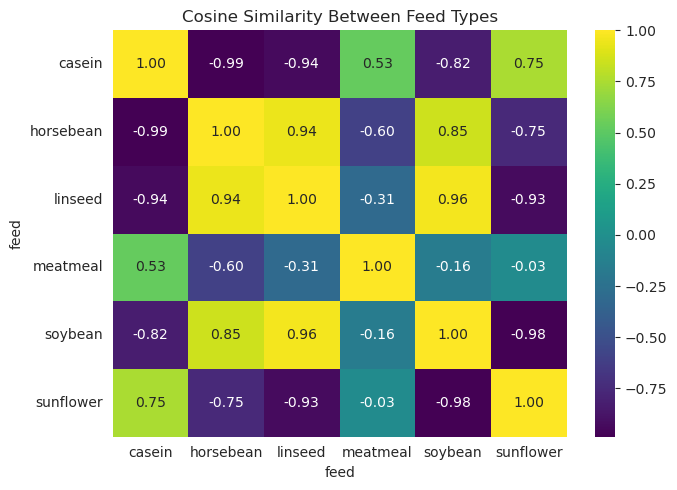

In [15]:
# ---- Cell 12: cosine similarity between feeds ----
cos_sim = pd.DataFrame(
    cosine_similarity(feed_scaled),
    index=feed_profile.index, columns=feed_profile.index)

plt.figure(figsize=(7, 5))
sns.heatmap(cos_sim, annot=True, fmt=".2f", cmap="viridis")
plt.title("Cosine Similarity Between Feed Types")
plt.tight_layout(); plt.show()

In [16]:
# ---- Cell 13: recommend similar feeds ----
def recommend_feeds(feed, top_n=3):
    feed = feed.strip().lower()
    if feed not in cos_sim.index:
        raise ValueError(f"'{feed}' not found. Options: {list(cos_sim.index)}")
    scores = cos_sim[feed].drop(feed).sort_values(ascending=False).head(top_n)
    return scores.rename("similarity").to_frame().round(3)

for f in cos_sim.index:
    print(f"\nFeeds similar to '{f}':")
    print(recommend_feeds(f, top_n=2))


Feeds similar to 'casein':
           similarity
feed                 
sunflower       0.751
meatmeal        0.534

Feeds similar to 'horsebean':
         similarity
feed               
linseed       0.939
soybean       0.849

Feeds similar to 'linseed':
           similarity
feed                 
soybean         0.964
horsebean       0.939

Feeds similar to 'meatmeal':
           similarity
feed                 
casein          0.534
sunflower      -0.033

Feeds similar to 'soybean':
           similarity
feed                 
linseed         0.964
horsebean       0.849

Feeds similar to 'sunflower':
          similarity
feed                
casein         0.751
meatmeal      -0.033


In [17]:
# ---- Cell 14: standardize & select top 3 features ----
# Ranked by total contribution to the principal components, weighted by variance explained.
scaler_a = StandardScaler()
A_scaled = pd.DataFrame(scaler_a.fit_transform(usarrests),
                        columns=usarrests.columns, index=usarrests.index)

pca_full = PCA().fit(A_scaled)
loadings = pd.DataFrame(pca_full.components_.T,
                        index=usarrests.columns,
                        columns=[f"PC{i+1}" for i in range(4)])

importance = (loadings.abs() * pca_full.explained_variance_ratio_).sum(axis=1)
top3 = importance.sort_values(ascending=False).head(3).index.tolist()
print("Feature importance:\n", importance.sort_values(ascending=False).round(3))
print("Top 3 features:", top3)

A_top3 = A_scaled[top3]

Feature importance:
 Murder      0.494
Assault     0.464
Rape        0.455
UrbanPop    0.428
dtype: float64
Top 3 features: ['Murder', 'Assault', 'Rape']


In [18]:
# ---- Cell 15: PCA to 2 components ----
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
A_pca = pca2.fit_transform(A_top3)
print("Explained variance ratio:", pca2.explained_variance_ratio_.round(3),
      f"(total {pca2.explained_variance_ratio_.sum():.1%})")

Explained variance ratio: [0.786 0.153] (total 93.9%)


Elbow k (K-Means): 2 | Lowest-BIC k (GMM): 2


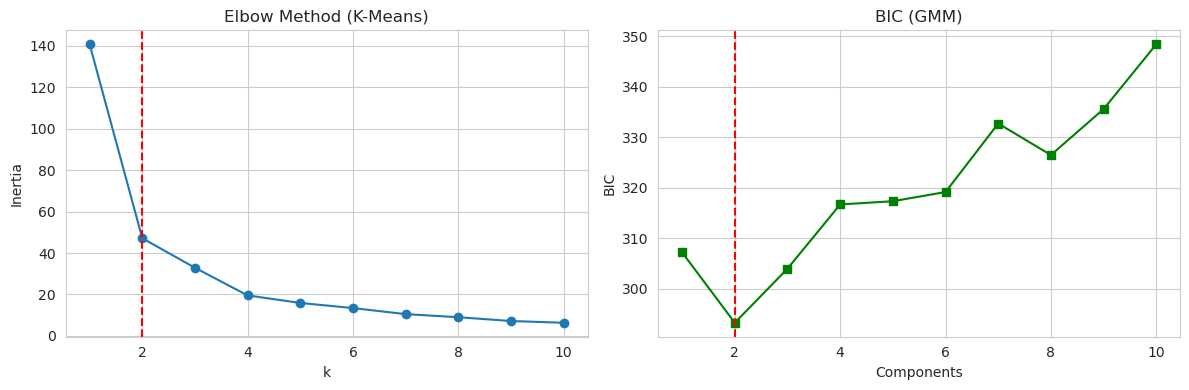

In [19]:
# ---- Cell 16: optimal k — Elbow (K-Means) and BIC (GMM) ----
k_range = range(1, 11)

inertias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(A_pca).inertia_
            for k in k_range]

bics = [GaussianMixture(n_components=k, covariance_type="full", n_init=5,
                        random_state=RANDOM_STATE).fit(A_pca).bic(A_pca)
        for k in k_range]

# Programmatic elbow: point farthest from the line joining the first and last inertia
x = np.array(list(k_range)); yv = np.array(inertias)
p1, p2 = np.array([x[0], yv[0]]), np.array([x[-1], yv[-1]])
dists = [np.abs(np.cross(p2 - p1, p1 - np.array([xi, yi]))) / np.linalg.norm(p2 - p1)
         for xi, yi in zip(x, yv)]
best_k_kmeans = int(x[np.argmax(dists)])
best_k_gmm = int(x[np.argmin(bics)])
print(f"Elbow k (K-Means): {best_k_kmeans} | Lowest-BIC k (GMM): {best_k_gmm}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_range, inertias, "o-"); ax[0].axvline(best_k_kmeans, ls="--", c="r")
ax[0].set(title="Elbow Method (K-Means)", xlabel="k", ylabel="Inertia")
ax[1].plot(k_range, bics, "s-", c="g"); ax[1].axvline(best_k_gmm, ls="--", c="r")
ax[1].set(title="BIC (GMM)", xlabel="Components", ylabel="BIC")
plt.tight_layout(); plt.show()

In [20]:
# ---- Cell 17: fit K-Means (hard) and GMM (probabilistic) ----
kmeans = KMeans(n_clusters=best_k_kmeans, n_init=10, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(A_pca)

gmm = GaussianMixture(n_components=best_k_gmm, covariance_type="full",
                      n_init=5, random_state=RANDOM_STATE)
gmm_labels = gmm.fit_predict(A_pca)
gmm_probs = gmm.predict_proba(A_pca)          # soft membership probabilities

results = pd.DataFrame({
    "PC1": A_pca[:, 0], "PC2": A_pca[:, 1],
    "KMeans": km_labels, "GMM": gmm_labels,
    "GMM_max_prob": gmm_probs.max(axis=1).round(3)}, index=usarrests.index)

print(results.head(10))
print("\nStates with uncertain GMM assignment (max prob < 0.80):")
print(results[results.GMM_max_prob < 0.80][["KMeans", "GMM", "GMM_max_prob"]])

                  PC1       PC2  KMeans  GMM  GMM_max_prob
State                                                     
Alabama      1.210191 -0.842277       1    1         0.995
Alaska       2.332187  1.539434       1    1         1.000
Arizona      1.518593  0.503363       1    1         0.972
Arkansas     0.177776 -0.328029       0    0         0.987
California   2.066000  1.285497       1    1         1.000
Colorado     1.276240  1.440888       1    1         0.995
Connecticut -1.643583 -0.180417       0    0         1.000
Delaware    -0.075572 -0.419830       0    0         0.998
Florida      2.859470 -0.427616       1    1         1.000
Georgia      1.861048 -0.891736       1    1         1.000

States with uncertain GMM assignment (max prob < 0.80):
Empty DataFrame
Columns: [KMeans, GMM, GMM_max_prob]
Index: []


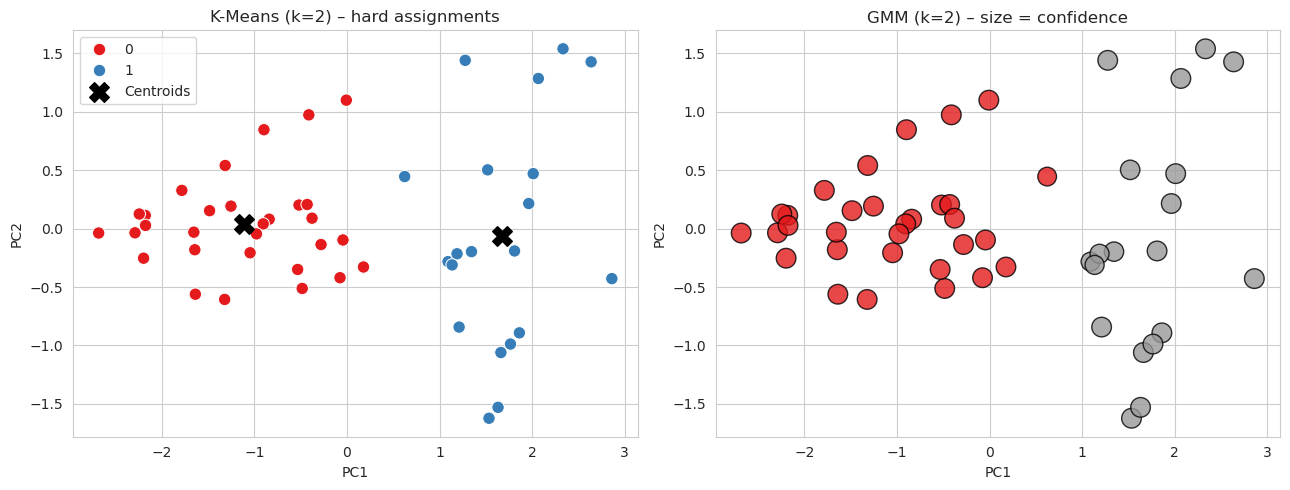

Silhouette  K-Means: 0.568
Silhouette  GMM    : 0.561
Agreement (Adjusted Rand Index): 0.920

K-Means cluster profiles (original units):
         Murder  Assault  UrbanPop  Rape
KMeans                                 
0          4.9    114.4      63.6  15.9
1         12.2    255.2      68.4  29.2


In [21]:
# ---- Cell 18: visualise & compare ----
from sklearn.metrics import silhouette_score, adjusted_rand_score

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(x="PC1", y="PC2", hue="KMeans", palette="Set1",
                data=results, s=80, ax=ax[0])
ax[0].scatter(*kmeans.cluster_centers_.T, c="black", marker="X", s=200, label="Centroids")
ax[0].set_title(f"K-Means (k={best_k_kmeans}) – hard assignments"); ax[0].legend()

# Marker size reflects GMM confidence
ax[1].scatter(results.PC1, results.PC2, c=results.GMM, cmap="Set1",
              s=40 + 160 * results.GMM_max_prob, alpha=0.8, edgecolor="k")
ax[1].set_title(f"GMM (k={best_k_gmm}) – size = confidence")
for a in ax:
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

# Quantitative comparison
print(f"Silhouette  K-Means: {silhouette_score(A_pca, km_labels):.3f}")
if best_k_gmm > 1:
    print(f"Silhouette  GMM    : {silhouette_score(A_pca, gmm_labels):.3f}")
print(f"Agreement (Adjusted Rand Index): {adjusted_rand_score(km_labels, gmm_labels):.3f}")

# Cluster profiles in original units
profile = usarrests.assign(KMeans=km_labels).groupby("KMeans").mean().round(1)
print("\nK-Means cluster profiles (original units):\n", profile)